In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --- Adım 1: Veri Seti Oluşturma ---
data = {
    'Sicaklik_C': [5, 12, 22, 30, 2, 18, 35, 8, 25, 15, 10, 28],
    'Nem_Orani_Yuzde': [80, 65, 50, 40, 85, 55, 35, 75, 45, 60, 70, 42],
    'Gunisigi_Saati': [4, 7, 10, 13, 3, 9, 14, 5, 11, 8, 6, 12],
    'HaftaIci_Mu_0_1': [1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1], # 1: Hafta içi, 0: Hafta sonu
    'Elektrik_Tuketimi_KWh': [45, 30, 25, 38, 50, 28, 42, 48, 32, 29, 40, 35] # Hedef (y)
}
df = pd.DataFrame(data)

In [2]:
df

,Sicaklik_C,Nem_Orani_Yuzde,Gunisigi_Saati,HaftaIci_Mu_0_1,Elektrik_Tuketimi_KWh
0,5,80,4,1,45
1,12,65,7,1,30
2,22,50,10,1,25
3,30,40,13,1,38
4,2,85,3,0,50
5,18,55,9,0,28
6,35,35,14,1,42
7,8,75,5,1,48
8,25,45,11,0,32
9,15,60,8,1,29


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Sicaklik_C,12.0,17.500000,10.570112,2.0,9.50,16.5,25.75,35.0
Nem_Orani_Yuzde,12.0,58.500000,16.643317,35.0,44.25,57.5,71.25,85.0
Gunisigi_Saati,12.0,8.500000,3.605551,3.0,5.75,8.5,11.25,14.0
HaftaIci_Mu_0_1,12.0,0.666667,0.492366,0.0,0.00,1.0,1.00,1.0
Elektrik_Tuketimi_KWh,12.0,36.833333,8.288364,25.0,29.75,36.5,42.75,50.0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Sicaklik_C             12 non-null     int64
 1   Nem_Orani_Yuzde        12 non-null     int64
 2   Gunisigi_Saati         12 non-null     int64
 3   HaftaIci_Mu_0_1        12 non-null     int64
 4   Elektrik_Tuketimi_KWh  12 non-null     int64
dtypes: int64(5)
memory usage: 612.0 bytes


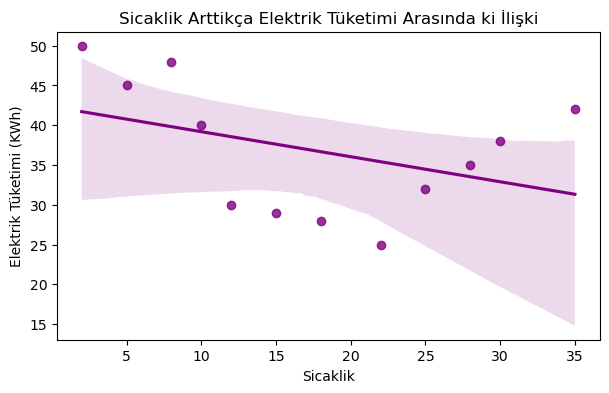

In [10]:
plt.figure(figsize=(7,4))
sns.regplot(x=df["Sicaklik_C"],y=df["Elektrik_Tuketimi_KWh"],data=df,color="purple")
plt.title("Sicaklik Arttikça Elektrik Tüketimi Arasında ki İlişki")
plt.xlabel("Sicaklik")
plt.ylabel("Elektrik Tüketimi (KWh)")
plt.show()


In [11]:
df.columns

Index(['Sicaklik_C', 'Nem_Orani_Yuzde', 'Gunisigi_Saati', 'HaftaIci_Mu_0_1',
       'Elektrik_Tuketimi_KWh'],
      dtype='object')

<Axes: xlabel='HaftaIci_Mu_0_1', ylabel='Elektrik_Tuketimi_KWh'>

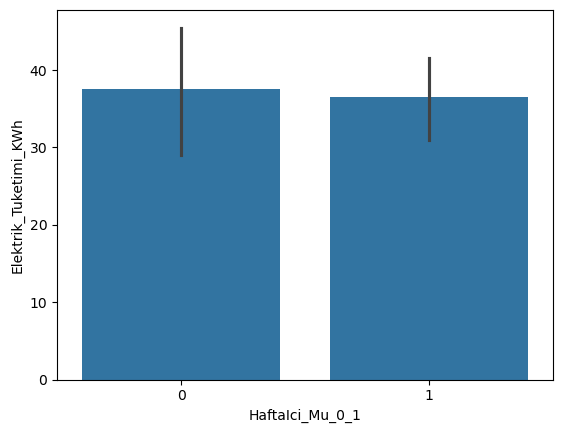

In [14]:
sns.barplot(x=df["HaftaIci_Mu_0_1"],y=df["Elektrik_Tuketimi_KWh"],data=df)

<Axes: >

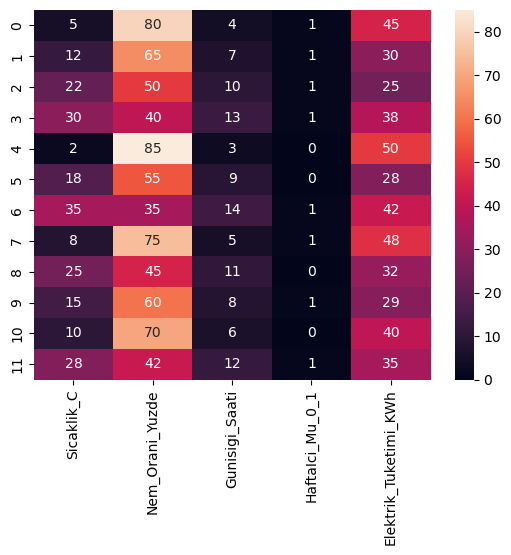

In [24]:
sns.heatmap(data=df,annot=True)


In [25]:
X=df.drop("Elektrik_Tuketimi_KWh",axis=1)
y=df["Elektrik_Tuketimi_KWh"]

In [26]:
X_train,X_test,y_train,y_test = train_test_split(X,y,random_state=42,test_size=0.2)

In [27]:
scaler = StandardScaler()

In [28]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [29]:
model = LinearRegression()

In [30]:
model.fit(X_train_scaled,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [ ]:
print()